# Problem 2 - Transformer from scratch

Chosen settings (assumed - the variants table was not in the brief): **d = 64**, **4 heads**, `d_ff = 256`; seeds **11, 23, 42** for Task A; Task B and the ablations use seed 11 (single run each, stated in the report).

Only my own attention, multi-head attention, encoder block and positional encodings are used; `F.scaled_dot_product_attention` appears only inside unit tests. Outputs go to `figures/`, `generated_samples.txt` and (idempotently) `../results.csv`.

In [1]:
import math, time, copy, random
import torch
import torch.nn as nn
import torch.nn.functional as F

D_MODEL = 64
NUM_HEADS = 4
D_FF = 4 * D_MODEL
SEEDS = (11, 23, 42)


class ScaledDotProductAttention(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

    def forward(self, q, k, v, mask=None):
        # q,k,v: (..., n, d_k); mask broadcastable to (..., n, n), True/1 = may attend
        scores = q @ k.transpose(-2, -1) * (q.size(-1) ** -0.5)      # (..., n, n)
        if mask is not None:
            keep = mask if mask.dtype == torch.bool else mask != 0
            scores = scores.masked_fill(~keep, float('-inf'))
        weights = self.dropout(torch.softmax(scores, dim=-1))        # rows sum to 1
        return weights @ v, weights                                  # (..., n, d_k)


def causal_mask(seq_len, device=None, dtype=torch.bool):
    return torch.tril(torch.ones(seq_len, seq_len, device=device, dtype=dtype))


def encoder_block_parameter_count(d_model, d_ff):
    return 4 * d_model * d_model + 2 * d_model * d_ff


def attention_example():
    q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
    k = q.clone()
    v = torch.tensor([[1., 0.], [0., 2.], [3., 4.]])
    return q, k, v


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.0):
        super().__init__()
        if d_model % num_heads:
            raise ValueError('d_model must be divisible by num_heads')
        self.d_model, self.num_heads, self.d_head = d_model, num_heads, d_model // num_heads
        self.W_q, self.W_k = nn.Linear(d_model, d_model), nn.Linear(d_model, d_model)
        self.W_v, self.W_o = nn.Linear(d_model, d_model), nn.Linear(d_model, d_model)
        self.attention = ScaledDotProductAttention(dropout)
        self.dropout = nn.Dropout(dropout)
        self.keep_attn, self.last_weights = False, None

    def forward(self, x, mask=None):
        B, n, _ = x.shape                                            # x: (B, n, d)
        # project, then split d into (heads, d_head) and move heads next to batch -> (B, h, n, d_head)
        q = self.W_q(x).view(B, n, self.num_heads, self.d_head).transpose(1, 2)
        k = self.W_k(x).view(B, n, self.num_heads, self.d_head).transpose(1, 2)
        v = self.W_v(x).view(B, n, self.num_heads, self.d_head).transpose(1, 2)
        if mask is not None and mask.dim() == 2:
            mask = mask[None, None]                                  # (1,1,n,n)
        out, w = self.attention(q, k, v, mask)                       # out (B,h,n,d_head), w (B,h,n,n)
        if self.keep_attn:
            self.last_weights = w.detach()
        out = out.transpose(1, 2).contiguous().view(B, n, self.d_model)   # concatenate heads -> (B,n,d)
        return self.dropout(self.W_o(out)), w


class EncoderBlock(nn.Module):
    """Pre-LayerNorm block: x + MHA(LN(x)); x + FFN(LN(x)); FFN width d_ff."""
    def __init__(self, d_model, d_ff, num_heads, dropout=0.1):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout),
                                nn.Linear(d_ff, d_model), nn.Dropout(dropout))

    def forward(self, x, mask=None):
        x = x + self.attn(self.norm1(x), mask)[0]
        return x + self.ff(self.norm2(x))


def sinusoidal_pe(n, d):
    pos = torch.arange(n, dtype=torch.float32).unsqueeze(1)           # (n,1)
    div = torch.exp(-math.log(10000.0) * torch.arange(0, d, 2, dtype=torch.float32) / d)   # (d/2,)
    pe = torch.zeros(n, d)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe

print(f'd={D_MODEL}, heads={NUM_HEADS}, d_ff={D_FF}, seeds={SEEDS}')

d=64, heads=4, d_ff=256, seeds=(11, 23, 42)


## Required datasets: UCI HAR (Task A) and Tiny Shakespeare (Task B)

The notebook follows the assignment's HAR download code (`urllib.request.urlretrieve(url, 'har.zip')` and `zipfile.ZipFile('har.zip').extractall('har')`). It reuses the Problem 1 extraction when available; otherwise it downloads and extracts under `problem2/har/`. Tiny Shakespeare is downloaded to `problem2/data/tinyshakespeare.txt`. HAR preprocessing uses the required nine-channel order, a four-subject validation split selected from training subjects by seed, training-only per-channel normalization, and the untouched official test split. Tiny Shakespeare builds its vocabulary from the full text, then uses the first 90% of characters for training and final 10% for validation without shuffling. Dataset files are cached locally and are not included in the submission.

In [2]:
from pathlib import Path
import os
import urllib.request
import zipfile

import numpy as np

NOTEBOOK_DIR = Path.cwd().resolve()
if NOTEBOOK_DIR.name != 'problem2':
    for parent in (NOTEBOOK_DIR, *NOTEBOOK_DIR.parents):
        candidate = parent / 'problem2'
        if candidate.is_dir():
            NOTEBOOK_DIR = candidate
            break
DATA_DIR = NOTEBOOK_DIR / 'data'
DATA_DIR.mkdir(parents=True, exist_ok=True)
HAR_DIR = NOTEBOOK_DIR / 'har'
HAR_URL = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
TINY_SHAKESPEARE_URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
CHANNELS = (
    'body_acc_x', 'body_acc_y', 'body_acc_z',
    'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
    'total_acc_x', 'total_acc_y', 'total_acc_z',
)

def _find_har_root(search_dir):
    for signal_dir in search_dir.rglob('Inertial Signals'):
        candidate = signal_dir.parent.parent
        if ((candidate / 'train' / 'y_train.txt').is_file()
                and (candidate / 'test' / 'y_test.txt').is_file()):
            return candidate
    return None


def load_har_arrays(dataset_root):
    def load_split(split):
        split_dir = dataset_root / split
        signal_dir = split_dir / 'Inertial Signals'
        x = np.stack([
            np.loadtxt(signal_dir / f'{channel}_{split}.txt', dtype=np.float32)
            for channel in CHANNELS
        ], axis=-1)
        y = np.loadtxt(split_dir / f'y_{split}.txt', dtype=np.int64)
        subjects = np.loadtxt(split_dir / f'subject_{split}.txt', dtype=np.int64)
        if x.ndim != 3 or x.shape[1:] != (128, 9):
            raise ValueError(f'Unexpected {split} signal shape: {x.shape}')
        if len(x) != len(y) or len(y) != len(subjects):
            raise ValueError(f'Mismatched {split} signals, labels and subjects')
        return x, y, subjects

    train_x, train_y, train_subjects = load_split('train')
    test_x, test_y, test_subjects = load_split('test')
    if not np.isin(train_y, np.arange(1, 7)).all() or not np.isin(test_y, np.arange(1, 7)).all():
        raise ValueError('HAR labels must be integers 1 through 6')
    return train_x, train_y, train_subjects, test_x, test_y, test_subjects


def prepare_har_data(seed, valid_subject_count=4):
    train_x, train_y, train_subjects, test_x, test_y, test_subjects = load_har_arrays(HAR_ROOT)
    unique_subjects = np.unique(train_subjects)
    if valid_subject_count >= len(unique_subjects):
        raise ValueError('Validation subjects must be fewer than training subjects')
    rng = np.random.default_rng(seed)
    valid_subjects = np.sort(rng.choice(unique_subjects, size=valid_subject_count, replace=False))
    is_valid = np.isin(train_subjects, valid_subjects)
    is_train = ~is_valid

    mean = train_x[is_train].mean(axis=(0, 1), keepdims=True)
    std = train_x[is_train].std(axis=(0, 1), keepdims=True)
    std = np.where(std < 1e-8, 1.0, std)

    data = {
        'train_x': ((train_x[is_train] - mean) / std).astype(np.float32),
        'train_y': train_y[is_train] - 1,
        'valid_x': ((train_x[is_valid] - mean) / std).astype(np.float32),
        'valid_y': train_y[is_valid] - 1,
        'test_x': ((test_x - mean) / std).astype(np.float32),
        'test_y': test_y - 1,
        'train_subjects': np.unique(train_subjects[is_train]),
        'valid_subjects': valid_subjects,
        'test_subjects': np.unique(test_subjects),
        'mean': mean.reshape(-1),
        'std': std.reshape(-1),
    }
    return data


os.chdir(NOTEBOOK_DIR)

# Reuse Problem 1's local extraction when available; otherwise download with the assignment snippet.
HAR_ROOT = _find_har_root(NOTEBOOK_DIR.parent / 'problem1' / 'har') or _find_har_root(HAR_DIR)
if HAR_ROOT is None:
    HAR_DIR.mkdir(parents=True, exist_ok=True)
    url = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
    urllib.request.urlretrieve(url, 'har.zip')
    zipfile.ZipFile('har.zip').extractall('har')

    # The outer archive may contain a second archive with the actual dataset.
    for nested_archive in HAR_DIR.rglob('*.zip'):
        with zipfile.ZipFile(nested_archive) as archive:
            archive.extractall(nested_archive.parent)
    HAR_ROOT = _find_har_root(HAR_DIR)
if HAR_ROOT is None:
    raise FileNotFoundError(f'Could not locate UCI HAR Dataset under {HAR_DIR}')

har = prepare_har_data(seed=SEEDS[0])
print('UCI HAR root:', HAR_ROOT)
print('HAR train:', har['train_x'].shape, '| validation:', har['valid_x'].shape,
      '| official test:', har['test_x'].shape)
print('HAR validation subjects for seed', SEEDS[0], ':', har['valid_subjects'].tolist())
assert har['train_x'].shape[1:] == (128, 9)
assert har['test_x'].shape == (2947, 128, 9)
assert not set(har['train_subjects']) & set(har['valid_subjects'])
assert np.isfinite(har['train_x']).all() and np.isfinite(har['valid_x']).all() and np.isfinite(har['test_x']).all()

# Tiny Shakespeare: vocabulary uses the whole corpus; split is chronological, with no shuffle.
SHAKESPEARE_PATH = DATA_DIR / 'tinyshakespeare.txt'
if not SHAKESPEARE_PATH.exists():
    print('Downloading Tiny Shakespeare...')
    with urllib.request.urlopen(TINY_SHAKESPEARE_URL, timeout=60) as response:
        SHAKESPEARE_PATH.write_bytes(response.read())
text = SHAKESPEARE_PATH.read_text(encoding='utf-8')
if not text:
    raise ValueError('Tiny Shakespeare text file is empty')

vocabulary = sorted(set(text))
if len(vocabulary) != 65:
    raise ValueError(f'Expected Tiny Shakespeare vocabulary size 65, got {len(vocabulary)}')
char_to_id = {char: index for index, char in enumerate(vocabulary)}
id_to_char = {index: char for char, index in char_to_id.items()}
encoded_text = np.fromiter((char_to_id[char] for char in text), dtype=np.int64, count=len(text))
split_index = int(0.9 * len(encoded_text))
train_data = torch.from_numpy(encoded_text[:split_index].copy())
valid_data = torch.from_numpy(encoded_text[split_index:].copy())
assert len(train_data) + len(valid_data) == len(text)
assert len(train_data) == split_index and len(valid_data) == len(text) - split_index
assert train_data.numel() > 0 and valid_data.numel() > 0

print('Tiny Shakespeare file:', SHAKESPEARE_PATH)
print('Characters:', len(text), '| vocabulary:', len(vocabulary))
print('Train characters:', len(train_data), '| validation characters:', len(valid_data))
print('Vocabulary preview:', repr(''.join(vocabulary[:20])))

UCI HAR root: /content/har/UCI HAR Dataset
HAR train: (5891, 128, 9) | validation: (1461, 128, 9) | official test: (2947, 128, 9)
HAR validation subjects for seed 11 : [5, 17, 25, 28]
Tiny Shakespeare file: /content/data/tinyshakespeare.txt
Characters: 1115394 | vocabulary: 65
Train characters: 1003854 | validation characters: 111540
Vocabulary preview: "\n !$&',-.3:;?ABCDEFG"


In [3]:
# ---- Task 1 unit tests (assert cells) ----
torch.manual_seed(0)
sdpa = ScaledDotProductAttention()
qr, kr, vr = torch.randn(2, 3, 10, 16), torch.randn(2, 3, 10, 16), torch.randn(2, 3, 10, 16)
out, w = sdpa(qr, kr, vr)
assert torch.allclose(w.sum(-1), torch.ones(2, 3, 10), atol=1e-5), 'rows must sum to 1'
assert torch.allclose(out, F.scaled_dot_product_attention(qr, kr, vr), atol=1e-5), 'must match torch SDPA'
cm = causal_mask(10)
out_c, w_c = sdpa(qr, kr, vr, mask=cm)
assert torch.allclose(out_c, F.scaled_dot_product_attention(qr, kr, vr, is_causal=True), atol=1e-5)
assert torch.all(w_c.masked_select(~cm.expand_as(w_c)) == 0), 'no weight on future positions'
assert torch.allclose(w_c.sum(-1), torch.ones(2, 3, 10), atol=1e-5)
print('row sums = 1, matches F.scaled_dot_product_attention (plain and causal), future weights are exactly 0.')

row sums = 1, matches F.scaled_dot_product_attention (plain and causal), future weights are exactly 0.


## Hand calculation: three tokens, dimension 2

`Q = K = [[1,0],[0,1],[1,1]]`, `V = [[1,0],[0,2],[3,4]]`. Scores = `Q K^T / sqrt(2)`, row-wise softmax, times `V`.

In [4]:
q, k, v = attention_example()
scale = q.size(-1) ** -0.5
scores = q @ k.T * scale
weights = torch.softmax(scores, dim=-1)
hand_output = weights @ v

expected_scores = torch.tensor([[0.7071068, 0.0, 0.7071068], [0.0, 0.7071068, 0.7071068], [0.7071068, 0.7071068, 1.4142135]])
expected_weights = torch.tensor([[0.4011121, 0.1977758, 0.4011121], [0.1977758, 0.4011121, 0.4011121], [0.2482551, 0.2482551, 0.5034898]])
expected_output = torch.tensor([[1.6044484, 2.0000000], [1.4011121, 2.4066725], [1.7587246, 2.5104694]])
assert torch.allclose(scores, expected_scores, atol=1e-6)
assert torch.allclose(weights, expected_weights, atol=1e-6)
assert torch.allclose(hand_output, expected_output, atol=1e-5)
code_output, code_weights = ScaledDotProductAttention()(q, k, v)
assert torch.allclose(code_output, hand_output, atol=1e-6) and torch.allclose(code_weights, weights, atol=1e-6)
assert torch.allclose(code_output, F.scaled_dot_product_attention(q, k, v), atol=1e-5)
print('scores=\n', scores, '\nweights=\n', weights, '\noutput=\n', code_output)
print('Hand calculation, custom code and PyTorch reference agree.')

scores=
 tensor([[0.7071, 0.0000, 0.7071],
        [0.0000, 0.7071, 0.7071],
        [0.7071, 0.7071, 1.4142]]) 
weights=
 tensor([[0.4011, 0.1978, 0.4011],
        [0.1978, 0.4011, 0.4011],
        [0.2483, 0.2483, 0.5035]]) 
output=
 tensor([[1.6044, 2.0000],
        [1.4011, 2.4067],
        [1.7587, 2.5105]])
Hand calculation, custom code and PyTorch reference agree.


## Multi-head attention, encoder block and parameter count

In [5]:
# ---- Task 2: shapes + parameter count reconciliation ----
mask = causal_mask(3)
_, cw = ScaledDotProductAttention()(q, k, v, mask=mask)
assert torch.all(cw.triu(1) == 0)

for d, dff, heads in ((64, 256, 4), (128, 512, 4)):
    blk = EncoderBlock(d, dff, heads, dropout=0.0)
    x = torch.randn(2, 7, d)
    with torch.no_grad(): y = blk(x)
    assert y.shape == x.shape
    weights_only = encoder_block_parameter_count(d, dff)           # 4d^2 + 2*d*d_ff
    biases = 4 * d + dff + d                                       # W_q,W_k,W_v,W_o biases + FFN biases
    layernorm = 2 * 2 * d                                          # two LayerNorms, gamma+beta
    total = sum(p.numel() for p in blk.parameters())
    assert total == weights_only + biases + layernorm
    print(f'd={d}, d_ff={dff}: weights {weights_only:,} + biases {biases:,} + LayerNorm {layernorm:,} = {total:,}')
assert encoder_block_parameter_count(128, 512) == 196_608 and encoder_block_parameter_count(64, 256) == 49_152

pe = sinusoidal_pe(128, D_MODEL)
assert pe.shape == (128, D_MODEL) and abs(pe[0, 0]) < 1e-6 and abs(pe[0, 1] - 1) < 1e-6
print('sinusoidal PE shape and first row OK')

d=64, d_ff=256: weights 49,152 + biases 576 + LayerNorm 256 = 49,984
d=128, d_ff=512: weights 196,608 + biases 1,152 + LayerNorm 512 = 198,272
sinusoidal PE shape and first row OK


In [6]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = NOTEBOOK_DIR.parent
RESULTS_CSV = ROOT / 'results.csv'
FIG = NOTEBOOK_DIR / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
print('Figures will be saved to:', FIG.resolve())
COLUMNS = ['problem','model','seed','seq_len','test_acc','macro_f1','test_mse','params',
           'sec_per_epoch','val_loss_nats','bits_per_char','notes']
ACTIVITY_NAMES = ('walking', 'walking upstairs', 'walking downstairs', 'sitting', 'standing', 'laying')
print('device:', DEVICE)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()

def log_row(**kw):
    row = {c: ('' if kw.get(c) is None else str(kw.get(c))) for c in COLUMNS}
    df = (pd.read_csv(RESULTS_CSV, dtype=str, keep_default_na=False)
          if RESULTS_CSV.exists() else pd.DataFrame(columns=COLUMNS))
    same = np.ones(len(df), dtype=bool)
    for k in ['problem', 'model', 'seed', 'seq_len', 'notes']:
        same &= (df[k] == row[k]).values
    pd.concat([df[~same], pd.DataFrame([row])], ignore_index=True)[COLUMNS].to_csv(RESULTS_CSV, index=False)

device: cuda


## Task A - encoder classifier on UCI HAR

Each window (128 x 9) is cut into 16 patches of 8 steps (8 x 9 = 72 values), linearly embedded to d = 64, a learned CLS token is prepended, positional information is added (**none / sinusoidal / learned**), 2 pre-LN encoder blocks (4 heads, d_ff = 256, dropout 0.1) process the 17 tokens and the CLS output is classified. Same data split, optimiser (Adam 1e-3), batch size (64), epochs (20) and gradient clipping (1.0) as Problem 1; the best-validation epoch is evaluated on test.

pos=none    seed=11 acc=0.9043 f1=0.9034 0.74s/epoch
pos=none    seed=23 acc=0.9264 f1=0.9265 0.76s/epoch
pos=none    seed=42 acc=0.9206 f1=0.9210 0.73s/epoch
pos=sin     seed=11 acc=0.9169 f1=0.9174 0.74s/epoch
pos=sin     seed=23 acc=0.9169 f1=0.9173 0.75s/epoch
pos=sin     seed=42 acc=0.9077 f1=0.9082 0.77s/epoch
pos=learned seed=11 acc=0.8921 f1=0.8883 0.80s/epoch
pos=learned seed=23 acc=0.9291 f1=0.9289 0.77s/epoch
pos=learned seed=42 acc=0.9070 f1=0.9068 0.74s/epoch
         acc_mean  acc_std  f1_mean  params  sec_per_epoch
pos                                                       
none       0.9171   0.0114   0.9170  105222         0.7440
sin        0.9138   0.0053   0.9143  105222         0.7504
learned    0.9094   0.0186   0.9080  106310         0.7696

Problem 1 (h=32):
       acc_mean  acc_std  params  sec_per_epoch
model                                          
GRU      0.8889   0.0049    4326         0.2235
LSTM     0.8731   0.0090    5702         0.2379
RNN      0.8116  

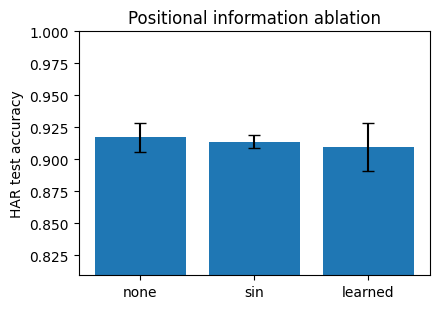

In [7]:
class HAREncoder(nn.Module):
    def __init__(self, pos='sin', d=D_MODEL, heads=NUM_HEADS, layers=2, patch=8, dropout=0.1):
        super().__init__()
        self.patch, self.pos_kind = patch, pos
        self.embed = nn.Linear(patch * 9, d)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        n_tok = 128 // patch + 1
        if pos == 'sin':       self.register_buffer('pe', sinusoidal_pe(n_tok, d))
        elif pos == 'learned': self.pe = nn.Parameter(torch.randn(n_tok, d) * 0.02)
        else:                  self.register_buffer('pe', torch.zeros(n_tok, d))
        self.blocks = nn.ModuleList([EncoderBlock(d, 4 * d, heads, dropout) for _ in range(layers)])
        self.norm, self.head = nn.LayerNorm(d), nn.Linear(d, 6)

    def forward(self, x):                                   # x (B,128,9)
        B = x.size(0)
        z = self.embed(x.reshape(B, 128 // self.patch, self.patch * 9))     # (B,16,d)
        z = torch.cat([self.cls.expand(B, -1, -1), z], dim=1) + self.pe     # (B,17,d)
        for b in self.blocks: z = b(z)
        return self.head(self.norm(z[:, 0]))                # classify from CLS

_raw_load = load_har_arrays; _raw_cache = {}
def load_har_arrays(root):
    if root not in _raw_cache: _raw_cache[root] = _raw_load(root)
    return _raw_cache[root]

@torch.no_grad()
def predict(model, x, bs=512):
    model.eval()
    return torch.cat([model(x[i:i + bs]).argmax(-1) for i in range(0, len(x), bs)]).cpu().numpy()

def train_har_encoder(pos, seed, epochs=20, bs=64, lr=1e-3, clip=1.0):
    set_seed(seed); d = prepare_har_data(seed)
    D = {k: torch.tensor(d[k]).to(DEVICE) for k in ('train_x', 'train_y', 'valid_x', 'valid_y', 'test_x', 'test_y')}
    model = HAREncoder(pos).to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=lr)
    best, state, times = -1.0, None, []
    for ep in range(epochs):
        model.train(); sync(); t0 = time.time(); perm = torch.randperm(len(D['train_x']), device=DEVICE)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(D['train_x'][idx]), D['train_y'][idx])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), clip); opt.step()
        sync(); times.append(time.time() - t0)
        va = float((predict(model, D['valid_x']) == D['valid_y'].cpu().numpy()).mean())
        if va > best: best, state = va, copy.deepcopy(model.state_dict())
    model.load_state_dict(state)
    y = D['test_y'].cpu().numpy(); p = predict(model, D['test_x'])
    return dict(pos=pos, seed=seed, test_acc=float((p == y).mean()), macro_f1=float(f1_score(y, p, average='macro')),
                params=sum(x.numel() for x in model.parameters()), sec_per_epoch=float(np.mean(times)))

A_RES = []
for pos in ('none', 'sin', 'learned'):
    for seed in SEEDS:
        r = train_har_encoder(pos, seed); A_RES.append(r)
        log_row(problem='P2A', model=f'Encoder-{pos}', seed=seed, seq_len=128, test_acc=r['test_acc'], macro_f1=r['macro_f1'],
                params=r['params'], sec_per_epoch=r['sec_per_epoch'], notes='HAR encoder patch=8 epochs=20')
        print(f"pos={pos:7s} seed={seed} acc={r['test_acc']:.4f} f1={r['macro_f1']:.4f} {r['sec_per_epoch']:.2f}s/epoch")
a_df = pd.DataFrame(A_RES)
a_tab = a_df.groupby('pos').agg(acc_mean=('test_acc','mean'), acc_std=('test_acc','std'), f1_mean=('macro_f1','mean'),
                                params=('params','first'), sec_per_epoch=('sec_per_epoch','mean')).loc[['none','sin','learned']]
print(a_tab.round(4))

# comparison with the Problem 1 models (read from results.csv written by problem1.ipynb)
res = pd.read_csv(RESULTS_CSV)
p1 = res[(res.problem == 'P1') & res.notes.fillna('').str.startswith('HAR main')]
if len(p1):
    print('\nProblem 1 (h=32):'); print(p1.groupby('model').agg(acc_mean=('test_acc','mean'), acc_std=('test_acc','std'),
          params=('params','first'), sec_per_epoch=('sec_per_epoch','mean')).round(4))
else:
    print('Run problem1.ipynb first to fill the Problem 1 comparison rows.')
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(a_tab.index, a_tab.acc_mean, yerr=a_tab.acc_std, capsize=4); ax.set_ylim(a_tab.acc_mean.min() - .1, 1)
ax.set_ylabel('HAR test accuracy'); ax.set_title('Positional information ablation'); fig.tight_layout()
fig.savefig(FIG / 'taskA_pos_ablation.png', dpi=150); plt.show()

## Task B - character-level causal language model (Tiny Shakespeare)

Context 128, d = 64, 4 heads, 4 layers, d_ff = 256, dropout 0.1, sinusoidal positions, pre-LN blocks, AdamW (lr 1e-3, 100 warm-up steps then cosine), batch 64, 5000 iterations. Validation loss is the mean cross-entropy over all non-overlapping 128-character windows of the final 10 % of the text. Bits per character = nats / ln 2.

heads=4 causal=True it=  250 train=2.876 val=2.450
heads=4 causal=True it= 4750 train=1.781 val=1.806
heads=4 causal=True it= 5000 train=1.780 val=1.804
validation loss 1.8043 nats = 2.6030 bits/char (uniform guess: 4.174 nats); params 208,449


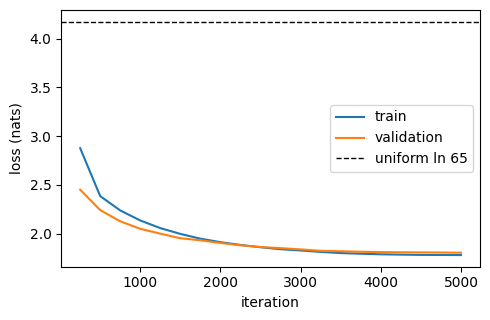

In [8]:
CTX, VOCAB = 128, len(vocabulary)

class CharLM(nn.Module):
    def __init__(self, ctx=CTX, d=D_MODEL, heads=NUM_HEADS, layers=4, dropout=0.1, causal=True):
        super().__init__()
        self.ctx, self.causal = ctx, causal
        self.tok = nn.Embedding(VOCAB, d)
        self.register_buffer('pe', sinusoidal_pe(ctx, d))
        self.register_buffer('mask', causal_mask(ctx))
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d, 4 * d, heads, dropout) for _ in range(layers)])
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, VOCAB)

    def forward(self, idx):                                  # idx (B,n) -> logits (B,n,V)
        n = idx.size(1)
        z = self.drop(self.tok(idx) + self.pe[:n])
        m = self.mask[:n, :n] if self.causal else None
        for b in self.blocks: z = b(z, m)
        return self.head(self.ln(z))

def get_batch(data, bs, gen):
    ix = torch.randint(len(data) - CTX - 1, (bs,), generator=gen)
    x = torch.stack([data[i:i + CTX] for i in ix]); y = torch.stack([data[i + 1:i + CTX + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)

@torch.no_grad()
def val_loss(model, bs=64):
    model.eval(); n = (len(valid_data) - 1) // CTX
    xs = torch.stack([valid_data[i * CTX:(i + 1) * CTX] for i in range(n)])
    ys = torch.stack([valid_data[i * CTX + 1:(i + 1) * CTX + 1] for i in range(n)])
    tot = 0.0
    for i in range(0, n, bs):
        lg = model(xs[i:i + bs].to(DEVICE))
        tot += F.cross_entropy(lg.reshape(-1, VOCAB), ys[i:i + bs].to(DEVICE).reshape(-1), reduction='sum').item()
    return tot / (n * CTX)

def train_lm(heads=4, causal=True, iters=5000, seed=11, bs=64, lr=1e-3, eval_every=250, layers=4):
    set_seed(seed); gen = torch.Generator().manual_seed(seed)
    model = CharLM(heads=heads, causal=causal, layers=layers).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.99), weight_decay=0.01)
    hist, run, times = [], [], []
    for it in range(1, iters + 1):
        f = it / 100 if it <= 100 else 0.5 * (1 + math.cos(math.pi * (it - 100) / (iters - 100)))
        for g in opt.param_groups: g['lr'] = lr * max(f, 0.05)
        model.train(); sync(); t0 = time.time()
        x, y = get_batch(train_data, bs, gen)
        loss = F.cross_entropy(model(x).reshape(-1, VOCAB), y.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        sync(); times.append(time.time() - t0); run.append(loss.item())
        if it % eval_every == 0 or it == iters:
            hist.append((it, float(np.mean(run[-eval_every:])), val_loss(model)))
            print(f'heads={heads} causal={causal} it={it:5d} train={hist[-1][1]:.3f} val={hist[-1][2]:.3f}')
    return model, hist, float(np.mean(times))

main_model, main_hist, main_sec = train_lm(heads=4, causal=True, iters=5000)
final_val = main_hist[-1][2]; bpc = final_val / math.log(2)
n_params = sum(p.numel() for p in main_model.parameters())
log_row(problem='P2B', model='Transformer', seed=11, seq_len=CTX, params=n_params, sec_per_epoch=main_sec,
        val_loss_nats=final_val, bits_per_char=bpc, notes='Char LM main d=64 heads=4 layers=4 iters=5000 (sec_per_epoch = sec per iteration)')
print(f'validation loss {final_val:.4f} nats = {bpc:.4f} bits/char (uniform guess: {math.log(VOCAB):.3f} nats); params {n_params:,}')

it_, tr_, va_ = zip(*main_hist)
fig, ax = plt.subplots(figsize=(5, 3.3)); ax.plot(it_, tr_, label='train'); ax.plot(it_, va_, label='validation')
ax.axhline(math.log(VOCAB), ls='--', c='k', lw=1, label='uniform ln 65'); ax.set_xlabel('iteration'); ax.set_ylabel('loss (nats)'); ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'lm_learning_curve.png', dpi=150); plt.show()

### Generation (top-k 40) at temperature 0.2, 0.8, 1.5

In [9]:
@torch.no_grad()
def generate(model, n=500, temperature=0.8, top_k=40, seed=0, prompt='\n'):
    model.eval(); g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([[char_to_id[c] for c in prompt]], device=DEVICE)
    for _ in range(n):
        logits = model(idx[:, -CTX:])[:, -1] / temperature                     # (1,V)
        v, _ = torch.topk(logits, top_k); logits[logits < v[:, [-1]]] = float('-inf')
        nxt = torch.multinomial(torch.softmax(logits, -1).cpu(), 1, generator=g).to(DEVICE)
        idx = torch.cat([idx, nxt], dim=1)
    return ''.join(id_to_char[i] for i in idx[0].tolist())[len(prompt):]

samples = {}
with open(NOTEBOOK_DIR / 'generated_samples.txt', 'w', encoding='utf-8') as fh:
    for T in (0.2, 0.8, 1.5):
        samples[T] = generate(main_model, 500, T, 40, seed=0)
        fh.write(f'=== temperature {T} (top-k 40, 500 characters) ===\n{samples[T]}\n\n')
        print(f'--- T={T} ---\n{samples[T]}\n')

--- T=0.2 ---
The shall the shall the come the be the good the with the heart
The shall the be the so the have some to the die
The with the did the comme the so the sould the fair
The the come of the with the see and the death.

Second Clord the come of the be my lord,
The prove the the shall the stand the have and the word
That her the the commpent so the words the shall the will
The shall the see the sould the sentle the done.

KING RICHARD III:
I will the shall here the sould of the shall the come.

CORIOL

--- T=0.8 ---
thy for this with the do thee hand,
And gelst than of to givent beare his heave bein
To says him; that of to his percaices is
And trunk-dayam the here hother a made of the with scont
show the carre of my prace him fill my honours
Not me of me fleom with the me sto dim.

KING EDWARD IV:
Nor hath father, what do heard do liefter;
And for should to my range be since excures.

GLOUCESTER:
When the pinty rown of the partace fair betther.

BRUTUS:
All you which him.

QUEE

### Analysis (a): attention heatmaps

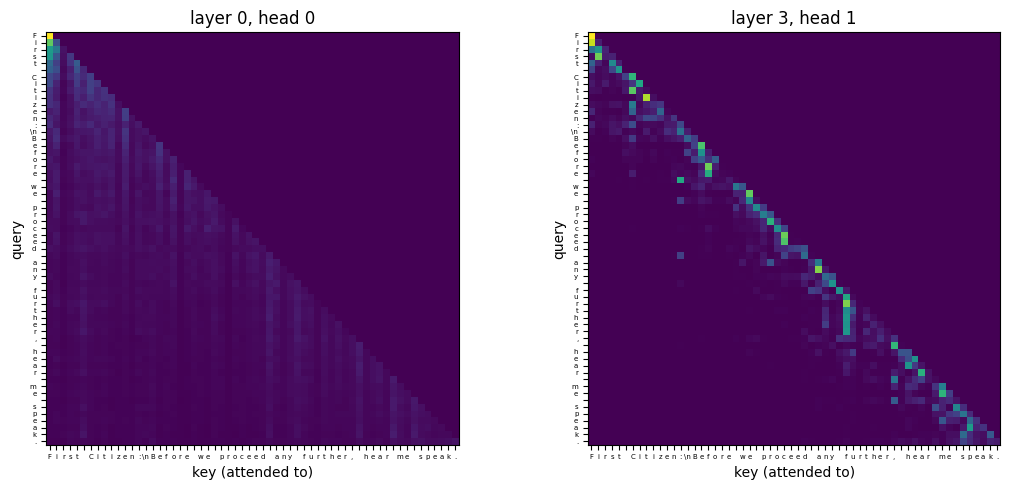

In [10]:
sentence = text[:60]                                           # "First Citizen:\nBefore we proceed any further, hear me speak."
ids = torch.tensor([[char_to_id[c] for c in sentence]], device=DEVICE)
for b in main_model.blocks: b.attn.keep_attn = True
main_model.eval()
with torch.no_grad(): main_model(ids)
labels = [c if c != '\n' else '\\n' for c in sentence]
picks = [(0, 0), (len(main_model.blocks) - 1, 1)]               # (layer, head)
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for ax, (L, Hh) in zip(axs, picks):
    w = main_model.blocks[L].attn.last_weights[0, Hh].cpu().numpy()
    ax.imshow(w, cmap='viridis'); ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=5); ax.set_yticklabels(labels, fontsize=5)
    ax.set_title(f'layer {L}, head {Hh}'); ax.set_xlabel('key (attended to)'); ax.set_ylabel('query')
fig.tight_layout(); fig.savefig(FIG / 'attention_heatmaps.png', dpi=170); plt.show()
for b in main_model.blocks: b.attn.keep_attn = False

### Analysis (b)(c): heads ablation and no causal mask

heads=1 causal=True it=  250 train=2.875 val=2.439
heads=1 causal=True it=  500 train=2.390 val=2.248
heads=1 causal=True it=  750 train=2.259 val=2.140
heads=1 causal=True it= 1000 train=2.172 val=2.077
heads=1 causal=True it= 1250 train=2.115 val=2.037
heads=1 causal=True it= 1500 train=2.080 val=2.011
heads=1 causal=True it= 1750 train=2.062 val=2.004
heads=1 causal=True it= 2000 train=2.054 val=2.000
heads=4 causal=True it=  250 train=2.876 val=2.451
heads=4 causal=True it=  500 train=2.387 val=2.246
heads=4 causal=True it=  750 train=2.247 val=2.139
heads=4 causal=True it= 1000 train=2.159 val=2.075
heads=4 causal=True it= 1250 train=2.102 val=2.043
heads=4 causal=True it= 1500 train=2.067 val=2.018
heads=4 causal=True it= 1750 train=2.048 val=2.011
heads=4 causal=True it= 2000 train=2.041 val=2.007
heads=8 causal=True it=  250 train=2.877 val=2.460
heads=8 causal=True it=  500 train=2.396 val=2.258
heads=8 causal=True it=  750 train=2.253 val=2.152
heads=8 causal=True it= 1000 tr

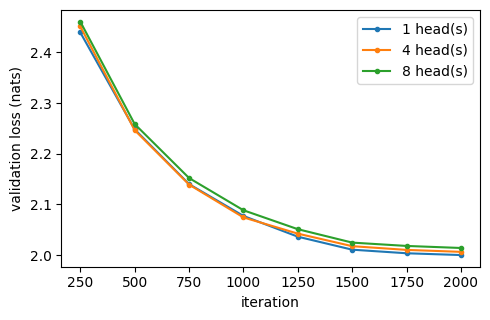

{1: 2.0004, 4: 2.0067, 8: 2.0143}


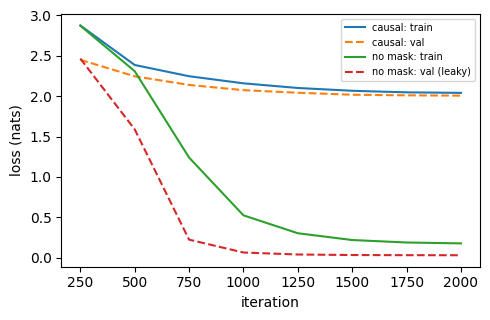

no-mask final train/val: (0.17553264343738556, 0.028726775665370796) | causal final train/val: (2.0409586181640624, 2.0066641140750576)
--- no-mask generation ---
 


































































































































































































.










































































































In [11]:
ABL_ITERS = 2000
# (b) heads = 1, 4, 8 at fixed d = 64 (d_head = 64, 16, 8);  (c) no causal mask
head_runs = {}
for h in (1, 4, 8):
    m, hist, sec = train_lm(heads=h, causal=True, iters=ABL_ITERS, eval_every=250); head_runs[h] = hist
    log_row(problem='P2B', model='Transformer', seed=11, seq_len=CTX, params=sum(p.numel() for p in m.parameters()),
            val_loss_nats=hist[-1][2], bits_per_char=hist[-1][2] / math.log(2), notes=f'Ablation heads={h} iters={ABL_ITERS}')
nomask_model, nomask_hist, _ = train_lm(heads=4, causal=False, iters=ABL_ITERS, eval_every=250)
log_row(problem='P2B', model='Transformer', seed=11, seq_len=CTX, params=sum(p.numel() for p in nomask_model.parameters()),
        val_loss_nats=nomask_hist[-1][2], bits_per_char=nomask_hist[-1][2] / math.log(2), notes=f'Ablation no causal mask iters={ABL_ITERS} (val loss leaks the future)')

fig, ax = plt.subplots(figsize=(5, 3.3))
for h, hist in head_runs.items(): ax.plot([a for a, _, _ in hist], [c for _, _, c in hist], marker='o', ms=3, label=f'{h} head(s)')
ax.set_xlabel('iteration'); ax.set_ylabel('validation loss (nats)'); ax.legend(); fig.tight_layout(); fig.savefig(FIG / 'ablation_heads.png', dpi=150); plt.show()
print({h: round(hist[-1][2], 4) for h, hist in head_runs.items()})

fig, ax = plt.subplots(figsize=(5, 3.3))
ref = head_runs[4]
ax.plot([a for a, _, _ in ref], [b for _, b, _ in ref], label='causal: train'); ax.plot([a for a, _, _ in ref], [c for _, _, c in ref], '--', label='causal: val')
ax.plot([a for a, _, _ in nomask_hist], [b for _, b, _ in nomask_hist], label='no mask: train'); ax.plot([a for a, _, _ in nomask_hist], [c for _, _, c in nomask_hist], '--', label='no mask: val (leaky)')
ax.set_xlabel('iteration'); ax.set_ylabel('loss (nats)'); ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(FIG / 'ablation_nomask.png', dpi=150); plt.show()
print('no-mask final train/val:', nomask_hist[-1][1:], '| causal final train/val:', ref[-1][1:])
with open(NOTEBOOK_DIR / 'generated_samples.txt', 'a', encoding='utf-8') as fh:
    s = generate(nomask_model, 300, 0.8, 40, seed=0)
    fh.write(f'=== (ablation) NO causal mask, temperature 0.8: generation is not a valid autoregressive model ===\n{s}\n')
    print('--- no-mask generation ---\n', s)

### Analysis (d): time and memory against context length

   context  sec_per_step    peak_MiB
0       64      0.013991   50.435059
1      128      0.014520   96.830078
2      256      0.019167  253.785156
3      512      0.048538  829.785156
log-log slope of time vs n: 0.58  (pure O(n^2) attention would be 2, O(n) projections/FFN would be 1)
log-log slope of memory vs n: 1.35


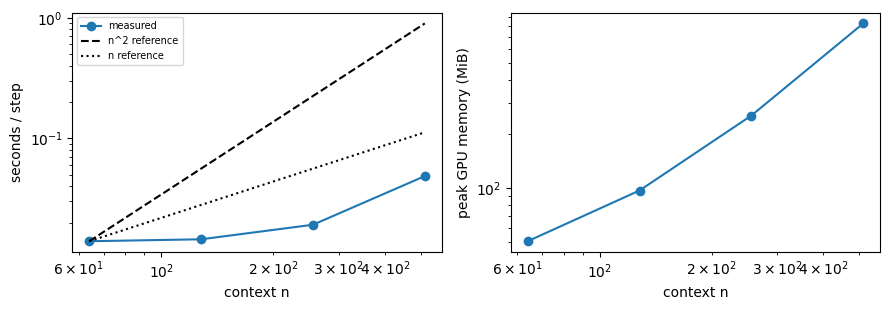

In [12]:
# (d) time and memory against context length n (forward+backward, batch 16, d=64, 4 layers, 4 heads)
def bench(n, bs=16, reps=10):
    m = CharLM(ctx=n).to(DEVICE); x = torch.randint(0, VOCAB, (bs, n), device=DEVICE)
    for _ in range(2): F.cross_entropy(m(x).reshape(-1, VOCAB), x.reshape(-1)).backward()
    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
    sync(); t0 = time.time()
    for _ in range(reps): m.zero_grad(); F.cross_entropy(m(x).reshape(-1, VOCAB), x.reshape(-1)).backward()
    sync(); t = (time.time() - t0) / reps
    mem = torch.cuda.max_memory_allocated() / 2**20 if torch.cuda.is_available() else float('nan')
    return t, mem

CTXS = [64, 128, 256, 512]
scale = [(n,) + bench(n) for n in CTXS]
sc = pd.DataFrame(scale, columns=['context', 'sec_per_step', 'peak_MiB']); print(sc)
slope_t = np.polyfit(np.log(sc.context), np.log(sc.sec_per_step), 1)[0]
print(f'log-log slope of time vs n: {slope_t:.2f}  (pure O(n^2) attention would be 2, O(n) projections/FFN would be 1)')
if sc.peak_MiB.notna().all(): print('log-log slope of memory vs n:', round(np.polyfit(np.log(sc.context), np.log(sc.peak_MiB), 1)[0], 2))
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
axs[0].loglog(sc.context, sc.sec_per_step, 'o-', label='measured'); axs[0].loglog(sc.context, sc.sec_per_step.iloc[0] * (sc.context / 64) ** 2, 'k--', label='n^2 reference'); axs[0].loglog(sc.context, sc.sec_per_step.iloc[0] * (sc.context / 64), 'k:', label='n reference')
axs[0].set_xlabel('context n'); axs[0].set_ylabel('seconds / step'); axs[0].legend(fontsize=7)
axs[1].loglog(sc.context, sc.peak_MiB, 'o-'); axs[1].set_xlabel('context n'); axs[1].set_ylabel('peak GPU memory (MiB)')
fig.tight_layout(); fig.savefig(FIG / 'time_memory_vs_context.png', dpi=150); plt.show()

## Analysis

*Write after the run, from the figures above (copied into the report).* Cover: interpretation of the two heatmaps (local / previous-character / newline heads?); heads 1 vs 4 vs 8 at fixed d (more heads means smaller d_head - what happened?); what removing the causal mask does (training loss collapses because the model can read the next character, generation fails); the measured time/memory growth against O(n^2 d); the temperature discussion (0.2 repetitive and safe, 0.8 balanced, 1.5 noisy); Task A: encoder vs best Problem 1 model on accuracy, parameters and time, and which positional option helped.